# Claimcheck, step by step

For developers who trust LangChain model profiles, it removes the guesswork about whether a model can really do what its profile says.

This notebook follows the course order: model, system prompt, tools, memory, images and audio. Cells that call the Gemini API use the free tier, so run them one at a time.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../src'))
os.chdir(os.path.abspath('..'))
from dotenv import load_dotenv
load_dotenv()
from claimcheck.config import settings
settings.model

'google_genai:gemini-3.1-flash-lite'

## 1. The model and `create_agent`

Every chat model in the project comes from one factory, `make_model`, which wraps `init_chat_model`. The smallest agent is a model with no tools.

In [2]:
from langchain.agents import create_agent
from claimcheck.models import make_model

model = make_model()
plain = create_agent(model, tools=[])
reply = plain.invoke({'messages': [{'role': 'user', 'content': 'Say hello in five words.'}]})
reply['messages'][-1].text

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


'Hello, it is nice meeting.'

## 2. The system prompt

The prompt sets the role, the scope, the order of work, the verdict rules, and how to treat tool output. Here the same model, with the prompt and no tools, is asked something out of scope.

In [3]:
from claimcheck.prompts import SYSTEM_PROMPT
print(SYSTEM_PROMPT)

You are Claimcheck. You check whether a chat model can really do what its LangChain profile and its models.dev record claim.

# Scope
- You investigate one provider and model per request.
- Only providers with free access are in scope. Today that is Google (google_genai). If a tool says a provider is out of scope, say so in scope_note and stop probing it.
- You do not give general model advice, rankings or opinions.
- If the request names no model, or get_claims says the model is unknown, do not probe. Ask the user for the exact model id, offering did_you_mean if present.

# How to investigate
1. Call list_findings, then get_claims. If the model is unknown to both sources, say so and do not probe.
2. Probe every capability on the langchain path, including ones claimed false, because a false claim that passes is wrong too. Probe parallel tool calls as an unclaimed observation.
3. Call check_provider_limits for token limits. Never test context size any other way.
4. If a langchain-path r

In [4]:
scoped = create_agent(model, tools=[], system_prompt=SYSTEM_PROMPT)
out = scoped.invoke({'messages': [{'role': 'user', 'content': 'Which model is best for writing code?'}]})
out['messages'][-1].text

"I am Claimcheck, an auditor for AI model claims. I do not provide rankings, opinions, or general model advice. My purpose is to verify whether a specific model's claimed capabilities are accurate.\n\nPlease provide the **exact model ID** (e.g., `gemini-1.5-flash`) you would like me to investigate, and specify which claimed capability you would like me to check."

## 3. Tools

A deterministic tool first: mapping a models.dev record to profile fields is pure Python and unit tested. Then the external-data tool `get_claims`, then one probe that calls the target model three times with a known answer.

In [5]:
from claimcheck.claims import models_dev_claims
models_dev_claims({'tool_call': True, 'modalities': {'input': ['text', 'image']}, 'limit': {'context': 1000}})

{'tool_calling': True,
 'image_inputs': True,
 'audio_inputs': False,
 'max_input_tokens': 1000}

In [6]:
import json
from claimcheck.tools import get_claims, probe_tool_calling
claims = json.loads(get_claims.invoke({'provider': 'google', 'model': 'gemma-4-26b-a4b-it'}))
[(r['field'], r['langchain'], r['models_dev']) for r in claims['claims']]

[('tool_calling', True, True),
 ('tool_choice', True, None),
 ('structured_output', True, True),
 ('image_inputs', True, True),
 ('audio_inputs', False, False),
 ('max_input_tokens', 262144, 262144),
 ('max_output_tokens', 32768, 32768)]

In [7]:
json.loads(probe_tool_calling.invoke({'provider': 'google', 'model': 'gemma-4-26b-a4b-it'}))

{'capability': 'tool_calling',
 'model': 'gemma-4-26b-a4b-it',
 'path': 'langchain',
 'outcome': 'pass',
 'passes': 3,
 'fails': 0,
 'errors': 0,
 'evidence_ids': ['probe-45882d37e0', 'probe-db645ccb39', 'probe-3e206461fe'],
 'sample_observed': "[{'name': 'get_weather', 'args': {'city': 'Paris'}}]",
 'sample_error': None,
 'live': True}

## 4. Short-term memory

A checkpointer stores each thread by `thread_id`, so a follow-up can say "the same model". The long-term store keeps saved findings across threads.

In [8]:
from langgraph.store.memory import InMemoryStore
from claimcheck.persistence import in_memory
from claimcheck.agent import build_agent
from claimcheck.tools import get_claims

agent = build_agent(checkpointer=in_memory(), store=InMemoryStore(), tools=[get_claims])
config = {'configurable': {'thread_id': 'notebook-memory'}}
first = agent.invoke({'messages': [{'role': 'user', 'content': 'What do the sources claim about audio input for google gemma-4-26b-a4b-it? Do not probe.'}]}, config)
report = first['structured_response']
report.model, [(c.field, c.claimed_langchain, c.claimed_models_dev) for c in report.claims]

('gemma-4-26b-a4b-it', [('audio_inputs', 'false', 'false')])

In [9]:
second = agent.invoke({'messages': [{'role': 'user', 'content': 'And for image input on the same model?'}]}, config)
# Turn two never names the model. The answer comes from the thread's memory.
report = second['structured_response']
report.model, [(c.field, c.claimed_langchain, c.claimed_models_dev) for c in report.claims]

('gemma-4-26b-a4b-it', [('image_inputs', 'true', 'true')])

## 5. Images and audio

The probes send images and audio with known answers. The same content blocks carry a user's screenshot or voice note to the agent.

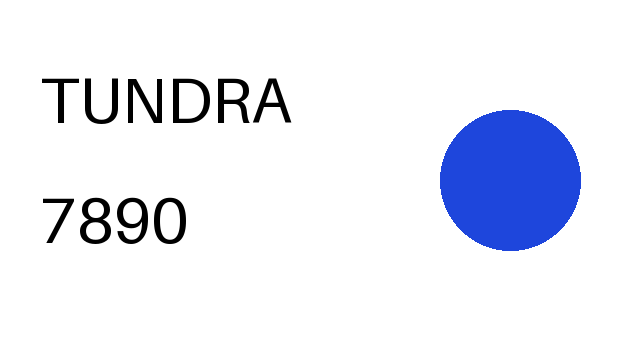

('TUNDRA', '7890', 'blue')

In [10]:
from IPython.display import Image, display
from claimcheck.probes.tasks import make_image_case
case = make_image_case(0)
display(Image(case.png, width=320))
case.word, case.number, case.color

In [11]:
import base64
from pathlib import Path
from langchain_core.messages import HumanMessage

shot = base64.b64encode(Path('evals/inputs/model_page.png').read_bytes()).decode()
voice = base64.b64encode(Path('evals/inputs/voice_request.wav').read_bytes()).decode()
msg = HumanMessage(content=[
    {'type': 'text', 'text': 'Which model id is on this page, and which model does the voice note ask about?'},
    {'type': 'image', 'base64': shot, 'mime_type': 'image/png'},
    {'type': 'audio', 'base64': voice, 'mime_type': 'audio/wav'},
])
model.invoke([msg]).text

'Based on the image and the audio provided:\n\n*   **Model ID on the page:** The page shows the model ID `gemma-4-26b-a4b-it`.\n*   **Model in the voice note:** The voice note asks about the "Google model Gemini 3.5 Flashlight."'

Audio goes to Gemini as an audio content block, with no separate transcription step. The full agent, with every tool, limits and approvals, runs from `python -m claimcheck.cli` or the web app.